#Regresion Lineal Multiple - Analisis de precios de laptops



##[link del github](https://github.com/manuxhino3-sketch/PROYECTO-2--RLM)

#1.Carga de datos y visualizacion de variables

##Importar el dataset elegido
en este caso elegimos un dataset que contiene datos de distintas marcas de laptops para analizar.

In [61]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("ironwolf437/laptop-price-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'laptop-price-dataset' dataset.
Path to dataset files: /kaggle/input/laptop-price-dataset


In [62]:
import pandas as pd
df = pd.read_csv("/root/.cache/kagglehub/datasets/ironwolf437/laptop-price-dataset/versions/1/laptop_price - dataset.csv")
#Selecionamos el archivo y lo ponemos en una variable)
#IMPORTANTE: ALGUNAS VECES SE GUARDA EN EL ROOT

In [63]:
display(df.head(10)) #Mostramos los primeros 10 elementos del dataset

,Company,Product,TypeName,Inches,ScreenResolution,CPU_Company,CPU_Type,CPU_Frequency (GHz),RAM (GB),Memory,GPU_Company,GPU_Type,OpSys,Weight (kg),Price (Euro)
0,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel,Core i5,2.3,8,128GB SSD,Intel,Iris Plus Graphics 640,macOS,1.37,1339.69
1,Apple,Macbook Air,Ultrabook,13.3,1440x900,Intel,Core i5,1.8,8,128GB Flash Storage,Intel,HD Graphics 6000,macOS,1.34,898.94
2,HP,250 G6,Notebook,15.6,Full HD 1920x1080,Intel,Core i5 7200U,2.5,8,256GB SSD,Intel,HD Graphics 620,No OS,1.86,575.00
3,Apple,MacBook Pro,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel,Core i7,2.7,16,512GB SSD,AMD,Radeon Pro 455,macOS,1.83,2537.45
4,Apple,MacBook Pro,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel,Core i5,3.1,8,256GB SSD,Intel,Iris Plus Graphics 650,macOS,1.37,1803.60
5,Acer,Aspire 3,Notebook,15.6,1366x768,AMD,A9-Series 9420,3.0,4,500GB HDD,AMD,Radeon R5,Windows 10,2.10,400.00
6,Apple,MacBook Pro,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel,Core i7,2.2,16,256GB Flash Storage,Intel,Iris Pro Graphics,Mac OS X,2.04,2139.97
7,Apple,Macbook Air,Ultrabook,13.3,1440x900,Intel,Core i5,1.8,8,256GB Flash Storage,Intel,HD Graphics 6000,macOS,1.34,1158.70
8,Asus,ZenBook UX430UN,Ultrabook,14.0,Full HD 1920x1080,Intel,Core i7 8550U,1.8,16,512GB SSD,Nvidia,GeForce MX150,Windows 10,1.30,1495.00
9,Acer,Swift 3,Ultrabook,14.0,IPS Panel Full HD 1920x1080,Intel,Core i5 8250U,1.6,8,256GB SSD,Intel,UHD Graphics 620,Windows 10,1.60,770.00


#2.Cambio de estructura de datos a matricial

In [64]:
#Seleccionamos las variables features como (x)
X = df[["RAM (GB)","CPU_Frequency (GHz)","Inches","Weight (kg)"]]
#Seleccionamos el objetivo como (y)
y = df[["Price (Euro)"]]
print("Variables features:")
display(x.shape)
print("Variable objetivo:")
display(y.shape)

Variables features:


(1275, 4)

Variable objetivo:


(1275, 1)

#3.Particion de train y test

In [65]:
import numpy as np
from sklearn.model_selection import train_test_split #Importamos la libreria
#Realizamos el split
X_train,X_test,y_train,y_test = train_test_split(
    X, # Variables features
    y, #Variable objetivo
    test_size=0.20, #Esto guarda 80% train y 20% test
    random_state = 42 #Esto pone la mezcla en el numero 42, haciendo que cada
#vez que se ejecute el codigo la mezcla sea igual.
)
#Impresion de las dimensiones
print("Dimensiones del Entrenamiento(Features):",X_train.shape)
print("Dimensiones del Entrenamiento(objetivo):",y_train.shape)
print("Dimensiones de la prueba(Features):",X_test.shape)
print("Dimensiones de la prueba(objetivo):",y_test.shape)

Dimensiones del Entrenamiento(Features): (1020, 4)
Dimensiones del Entrenamiento(objetivo): (1020, 1)
Dimensiones de la prueba(Features): (255, 4)
Dimensiones de la prueba(objetivo): (255, 1)


#4.Generación del modelo con los datos de Entrenamiento

In [66]:
from sklearn.linear_model import LinearRegression
modelo= LinearRegression() #Selecionamos que modelo usar, en este caso la regresion lineal
modelo.fit(X_train, y_train) #usamos las variables de entrenamiento para el modelo

print("\nModelo entrenado correctamente")


Modelo entrenado correctamente


#5.Evaluación del modelo con los datos de Entrenamiento

In [67]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
#predecir
pred_tr = modelo.predict(X_train)
#Medidas
r2_tr = r2_score(y_train,pred_tr)
mae_tr = mean_absolute_error(y_train,pred_tr)
rmse_tr = mean_squared_error(y_train, pred_tr) ** 0.5
print(f"""----METRICAS TRAINING----
 R²:{round(r2_tr,3)}
 MAE:{round(mae_tr,3)}
 RMSE:{round(rmse_tr,3)}
""")


----METRICAS TRAINING----
 R²:0.591
 MAE:323.72
 RMSE:446.972



#6. Evaluación del modelo con los datos de Test

In [68]:
#predecir
pred_test = modelo.predict(X_test)
#Medidas
r2_test = r2_score(y_test,pred_test)
mae_test = mean_absolute_error(y_test,pred_test)
rmse_test = mean_squared_error(y_test, pred_test) ** 0.5
print(f"""----METRICAS TRAINING----
 R²:{round(r2_test,3)}
 MAE:{round(mae_test,3)}
 RMSE:{round(rmse_test,3)}
""")

----METRICAS TRAINING----
 R²:0.646
 MAE:311.141
 RMSE:419.008



##Comparacion de entrenamiento vs test

In [69]:
#Realizamos una tabla para comparar
comparacion = pd.DataFrame({
    "Métrica":[ #Columna 1
        "R²",
        "MAE",
        "RMSE"
    ],
    "Train":[ #Columna 2
        r2_tr,
        mae_tr,
        rmse_tr
    ],
    "Test":[ #Columna 3
        r2_test,
        mae_test,
        rmse_test
    ]
})

print("Comparación de resultados:")
display(comparacion)

Comparación de resultados:


,Métrica,Train,Test
0,R²,0.591212,0.646274
1,MAE,323.719715,311.140692
2,RMSE,446.972285,419.008334


##Analisis de las variables mas importantes

In [70]:
coeficientes = pd.DataFrame({
    "Variable": X.columns,
    "Coeficiente": modelo.coef_[0] #Como la variable objetivo es bidimensional(1020,1) extraemos solamente
    #el 1020
})

coeficientes["Valor Absoluto"] = abs( #lo transformamos en su valor absoluto
                                     #para ver que tanto influye.
    coeficientes["Coeficiente"]
)

coeficientes = coeficientes.sort_values( #Acomodamos los valores en orden
                                        #descendente
    by="Valor Absoluto",
    ascending=False
)

print("Coeficientes del modelo:")
display(coeficientes)

print(
    "\nVariable más influyente:",
    coeficientes.iloc[0]["Variable"]
)

Coeficientes del modelo:


,Variable,Coeficiente,Valor Absoluto
1,CPU_Frequency (GHz),310.081094,310.081094
2,Inches,-94.431527,94.431527
0,RAM (GB),93.742816,93.742816
3,Weight (kg),32.932484,32.932484



Variable más influyente: CPU_Frequency (GHz)


##Graficos de coeficientes

/tmp/ipykernel_1361/2871944206.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


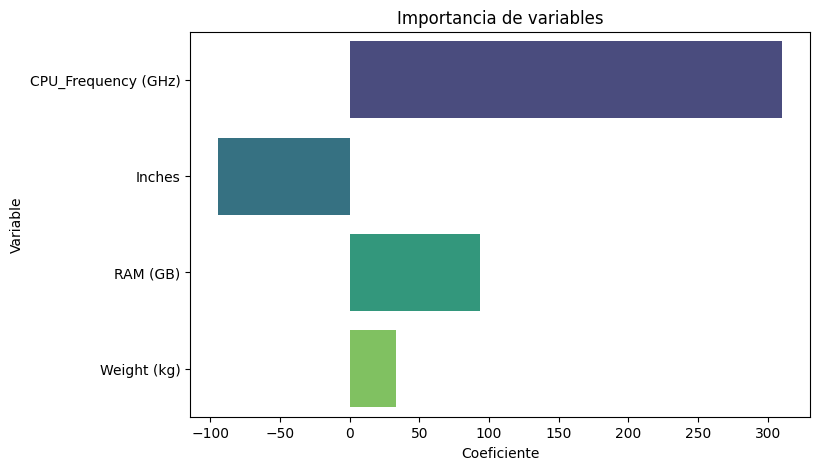

In [71]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8,5))

sns.barplot(
    data=coeficientes,
    x="Coeficiente",
    y="Variable",
    palette="viridis"
)

plt.title("Importancia de variables")
plt.xlabel("Coeficiente")
plt.ylabel("Variable")

plt.show()